# Adversarial Search: Solving Tic-Tac-Toe with Minimax Search and Alpha-Beta Pruning

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. __Optimal Decisions:__ Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. Monte Carlo Tree search: Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* __minimax search,__
* __minimax search with alpha-beta pruning,__ and
* __move ordering__. 

The search time (number if nodes explored) could be further improved by 
* __heuristic alpha-beta tree search__ (cut off search and use heuristic evaluation function to approximate utility), 
* __forward pruning__ (prune moves that appear poor), and
* __table lookups__ (for openings and end game).

The algorithms search the game tree and we could return a conditional plan (or partial plan if cut offs are used), but the implementation here only identifies and returns the optimal next move.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Recursive DFS algorithm for Minimax Search

See AIMA page 150. 

Note that the minimax search algorithm is very similar to AND-OR search where max does OR and min is represented by AND nodes.

In [3]:
import math

# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def minimax_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value(board, player)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
 
    return { "move": move, "value": value}

def max_value(state, player):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("max in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, return move with the largest value
    for a in actions(state):
        v2, a2 = min_value(result(state, player, a), player)
        if v2 > v:
            v, move = v2, a
    
    if DEBUG >= 2: print("max out: " + str(state) + str([v, move]) ) 
    return v, move

def min_value(state, player):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state if it is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print("min in: " + str(state) + str([v]) ) 
    if v is not None: return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value(result(state, other(player), a), player)
        if v2 < v:
            v, move = v2, a
    
    if DEBUG >= 2: print("min out: " + str(state) + str([v, move]) ) 
    return v, move

## Some Tests

### x is about to win (choose 8)

Board:


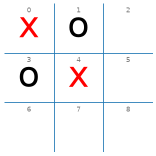


Number of nodes searched: 190


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 10.3 ms


In [4]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Nhận xét:** Minimax tìm được nước thắng `2` với giá trị `1`; thuật toán không ưu tiên thắng sớm, mà chọn nước tối ưu đầu tiên theo thứ tự duyệt.


Board:


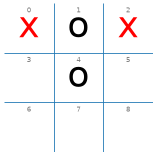


Number of nodes searched: 206


{'move': 7, 'value': 0}

CPU times: total: 15.6 ms
Wall time: 4.73 ms


In [5]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Nhận xét:** Minimax chọn ô `7` để hòa, giá trị tối ưu là `0`.


### A bad situation


Board:


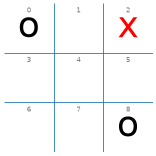


Number of nodes searched: 941


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 19.9 ms


In [6]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(minimax_search(board))

**Nhận xét:** Trong tình huống bất lợi, Minimax chọn ô `1` nhưng giá trị vẫn là `-1`, nghĩa là X không thể tránh thua nếu O chơi tối ưu.


### Empty board

Board:


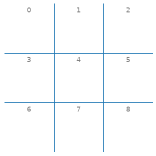

Number of nodes searched: 549946


{'move': 0, 'value': 0}

CPU times: total: 9.77 s
Wall time: 10.2 s


In [7]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(minimax_search(board))

**Nhận xét:** Trên bàn rỗng, Minimax xét `549,946` nút để xác nhận giá trị hòa `0`; tìm toàn bộ cây mất nhiều thời gian.


# Recursive DFS algorithm for Minimax Search with Alpha-Beta Pruning

See AIMA page 154. 

Adds alpha-beta pruning to minimax search. Alpha and beta are used to maintain bounds on the minimax value of a node in the form `[alpha, beta]`. alpha means that the value is at least that high and beta means that the actual value is at most that high. Subtrees below a node that are worse than the currently known bound do not need to be further explored and can be pruned. Max uses alpha and Min uses beta for pruning.

The implementation is for player 'x' returns a the optimal next move.

In [8]:
# global variables
DEBUG = 1 # 1 ... count nodes, 2 ... debug each node
COUNT = 0

def alpha_beta_search(board, player = 'x'):
    """start the search."""
    global DEBUG, COUNT
    COUNT = 0
    
    value, move = max_value_ab(board, player, -math.inf, +math.inf)
    
    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}") 
    
    return { "move": move, "value": value }

def max_value_ab(state, player, alpha, beta):
    """player's best move."""
    global DEBUG, COUNT
    COUNT += 1
       
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtracking.")
        return v, None
        
    v, move = -math.inf, None

    # check all possible actions in the state, update alpha and return move with the largest value
    for a in actions(state):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta)
        if DEBUG >= 2: print(f"max: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta:
            if DEBUG >= 2: print(f"     v>=beta ({v}>={beta}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

def min_value_ab(state, player, alpha, beta):
    """opponent's best response."""
    global DEBUG, COUNT
    COUNT += 1
    
    # return utility of state is a terminal state
    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: 
        if DEBUG >= 2: print(f"     found terminal state. backtacking.")
        return v, None
    
    v, move = +math.inf, None

    # check all possible actions in the state, update beta and return move with the smallest value
    for a in actions(state):
        v2, a2 = max_value_ab(result(state, other(player), a), player, alpha, beta)
        if DEBUG >= 2: print(f"min: {state} (backtracked) [alpha,beta]=[{alpha},{beta}] v={v2}")
        
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: 
            if DEBUG >= 2: print(f"     v<=alpha ({v}<={alpha}): pruning remaining subtree (actions). backtracking.")
            return v, move
    
    return v, move

## So sánh Minimax và Alpha-Beta trên cùng bốn bàn

Cả hai thuật toán được chạy trên cùng bốn trạng thái kiểm thử (X sắp thắng, X có thể hòa, tình huống bất lợi và bàn rỗng). Bảng ghi nước đi, giá trị Minimax, số nút đã thăm và thời gian thực tế của lần chạy này.

In [9]:
from time import perf_counter
from IPython.display import Markdown, display

comparison_boards = [
    ("X sắp thắng", ['x', 'o', ' ', 'o', 'x', ' ', ' ', ' ', ' ']),
    ("X có thể hòa", ['x', 'o', 'x', ' ', 'o', ' ', ' ', ' ', ' ']),
    ("Tình huống bất lợi", ['o', ' ', 'x', ' ', ' ', ' ', ' ', ' ', 'o']),
    ("Bàn rỗng", empty_board()),
]
comparison_rows = []
for board_name, test_board in comparison_boards:
    results = []
    for algorithm_name, search in [("Minimax", minimax_search), ("Alpha-Beta", alpha_beta_search)]:
        DEBUG = 0
        start = perf_counter()
        result_data = search(test_board.copy(), player='x')
        elapsed_ms = (perf_counter() - start) * 1000
        nodes = COUNT
        results.append(result_data)
        comparison_rows.append((board_name, algorithm_name, result_data["move"], result_data["value"], nodes, elapsed_ms))
    assert results[0]["value"] == results[1]["value"], f"Value mismatch on {board_name}"

rows = ["| Bàn cờ | Thuật toán | Nước đi | Giá trị Minimax | Số nút | Thời gian (ms) |", "| --- | --- | ---: | ---: | ---: | ---: |"]
rows.extend(f"| {name} | {algorithm} | {move} | {value} | {nodes:,} | {elapsed:.3f} |" for name, algorithm, move, value, nodes, elapsed in comparison_rows)
display(Markdown("\n".join(rows)))

| Bàn cờ | Thuật toán | Nước đi | Giá trị Minimax | Số nút | Thời gian (ms) |
| --- | --- | ---: | ---: | ---: | ---: |
| X sắp thắng | Minimax | 2 | 1 | 190 | 3.349 |
| X sắp thắng | Alpha-Beta | 2 | 1 | 61 | 1.128 |
| X có thể hòa | Minimax | 7 | 0 | 206 | 4.043 |
| X có thể hòa | Alpha-Beta | 7 | 0 | 101 | 1.677 |
| Tình huống bất lợi | Minimax | 1 | -1 | 941 | 16.742 |
| Tình huống bất lợi | Alpha-Beta | 1 | -1 | 238 | 4.546 |
| Bàn rỗng | Minimax | 0 | 0 | 549,946 | 10027.583 |
| Bàn rỗng | Alpha-Beta | 0 | 0 | 18,297 | 349.022 |

**Nhận xét:** Trên cả bốn bàn, Minimax và Alpha-Beta cho cùng giá trị tối ưu; Alpha-Beta chỉ cần xét ít nút hơn nhờ cắt các nhánh không thể làm đổi kết quả.

## Some Tests

### x is about to win (play 8)

Board:


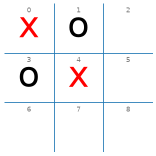


Number of nodes searched: 61


{'move': 2, 'value': 1}

CPU times: total: 0 ns
Wall time: 2.95 ms


In [10]:
DEBUG = 1 # count nodes without per-node trace

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

**Nhận xét:** Alpha-Beta cũng trả giá trị `1` cho bàn X sắp thắng; thứ tự duyệt không nhằm tìm đường thắng ngắn nhất.

### x can draw if it chooses 7

Board:


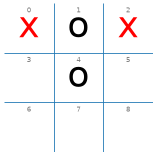


Number of nodes searched: 101


{'move': 7, 'value': 0}

CPU times: total: 0 ns
Wall time: 4.74 ms


In [11]:
DEBUG = 1

board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

**Nhận xét:** Alpha-Beta tìm được nước hòa `7`, giá trị `0`, và chỉ thăm `101` nút.


### o is about to win no matter what x does


Board:


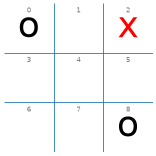


Number of nodes searched: 238


{'move': 1, 'value': -1}

CPU times: total: 15.6 ms
Wall time: 6.46 ms


In [12]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)

print()
%time display(alpha_beta_search(board))

**Nhận xét:** Alpha-Beta xác nhận thế cờ này có giá trị `-1`; X đi ô `1` nhưng vẫn buộc thua.


### Empty board: Only a draw an be guaranteed

Board:


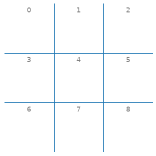

Number of nodes searched: 18297


{'move': 0, 'value': 0}

CPU times: total: 375 ms
Wall time: 367 ms


In [13]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Nhận xét:** Với cùng bàn rỗng, Minimax thăm `549,946` nút còn Alpha-Beta thăm `18,297`; hai thuật toán đều trả giá trị `0` (hòa).


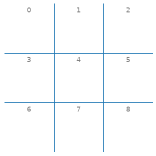

[4, 8, 6, 2, 0, 7, 5, 3, 1]

In [14]:
import numpy as np

def actions(board):
    """return possible actions as a vector ot indices"""
    actions = np.where(np.array(board) == ' ')[0].tolist()

    priority = [1,0,1,
                0,2,0,
                1,0,1]
    priority = [priority[i] for i in actions]
    
    actions =[a for _,a in sorted(zip(priority,actions), reverse=True)]
    
    return actions

board = empty_board()   
show_board(board)
actions(board)

### Empty board: Only a draw an be guaranteed

Board:


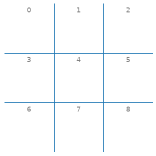

Number of nodes searched: 7275


{'move': 4, 'value': 0}

CPU times: total: 156 ms
Wall time: 150 ms


In [15]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%time display(alpha_beta_search(board))

**Nhận xét:** Trên bàn rỗng, Alpha-Beta thăm `18,297` nút với thứ tự ban đầu và `7,275` nút sau khi ưu tiên trung tâm/góc, giảm `11,022` nút (khoảng `60.2%`). Giá trị vẫn `0` (hòa); nước đi đổi từ `0` sang `4`, nhưng cả hai đều tối ưu. Thứ tự tốt tìm được nhánh mạnh sớm, cập nhật alpha/beta chặt hơn và cho phép cắt nhiều nhánh hơn.

## Experiments


### Minimax with Alpha-Beta Pruning vs. Random

In [16]:
DEBUG = 0

def alpha_beta_player(board, player = 'x'):
    return alpha_beta_search(board, player)["move"]

print("alpha-beta vs. random:")
%time display(play(alpha_beta_player, random_player))

print()
print("random vs. alpha-beta")
%time display(play(random_player, alpha_beta_player))

alpha-beta vs. random:


{'x': 98, 'o': 0, 'd': 2}

CPU times: total: 16.2 s
Wall time: 17.2 s

random vs. alpha-beta


{'x': 0, 'o': 87, 'd': 13}

CPU times: total: 4.19 s
Wall time: 4.34 s


**Nhận xét:** Trong lần chạy mới nhất, Alpha-Beta thắng `98`, hòa `2`, thua `0` khi đi trước; khi đi sau, thắng `87`, hòa `13`, thua `0`. Random không cố định seed nên kết quả có thể đổi giữa các lần chạy.

### Bảng tổng hợp kết quả (Mục 4 Lab 05)

| Tác tử / Thuật toán | Đối thủ | Số ván | Thắng | Hòa | Thua | Thời gian TB / nước đi |
| --- | --- | ---: | ---: | ---: | ---: | ---: |
| Alpha-Beta (đi trước - X) | Random | 100 | 98 | 2 | 0 | 89.09 ms |
| Alpha-Beta (đi sau - O) | Random | 100 | 87 | 13 | 0 | 89.09 ms |

*Thời gian trung bình mỗi nước đi lấy từ Wall time trung bình của alpha_beta_search trên bốn bàn kiểm thử: (1.128 + 1.677 + 4.546 + 349.022) / 4 = 89.093 ms.*


**Note on runtime:** Compared to AND-OR Search, Minimax search is slower, because AND-OR Search terminates once it finds the first subtree that has only goal nodes, buy Minimax search traverses the whole tree (minus what is pruned if alpha-beta pruning is used). 

Also, I was lazy and recreate the search tree every time the agent is asked for a move. The agent could create the tree with the Minimax values once and then use it to decide on actions. A problem could be that the tree may be too large to store. 